# 01: Setup & Exploratory Data Analysis

## Table of Contents

**Goal of Each Section**
1. **Setup & Load Data:** To setup necessary libraries and load in the data
2. **Dataset Overview & Data Quality:** To understand the shape and columns of the dataset, how clean the dataset is and whether they are missing/duplicate values
3. **Target Analysis & Temporal Analysis:** To understand the distribution of the labels and class balance, as well as how label coverage, illicit rate and transaction volume changes over time.
5. **Feature Analysis:** To understand the features with summary statistics, variance/skewness measures and class separation; To understand feature relationships e.g. correlations, redundant or useful variables, dealing with 165 features etc.; To understand temporal drift of features
6. **Graph EDA:** To understand the transaction graph's structure; scale, connectivity, degree distribution, and how connectivity relates to the illicit label; to establish concrete, data-grounded justification for the graph-based features engineered.
7. **Conclusion:** Summary of EDA findings and implications for preprocessing and validation; Hypothesis for feature engineering


## 1. Setup & Load Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

RANDOM_STATE = 42
DATA_DIR = Path("../data")

print("Libraries loaded")


Libraries loaded


In [2]:
# For reproducibility
np.random.seed(RANDOM_STATE) 

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")


## 2. Dataset Overview & Data Quality
**Section Findings:**
- Dataset has 165 annonymized, pre-normalized features in addition to `txId`, `time_step` and `label`.
- Dataset does not require cleaning. There are no duplicate rows and no missing or infinite values in the features. The missing values in `label` (78%) is expected from the project brief, reflecting the real-world nature where only a subset of the data is confirmed illicit/licit. Training will only be done on the labeled subset. The unlabeled majority will be used as a source of graph structure.

**Follow Up Decisions:**
- No imputation / cleaning required.

### 2.1 Data Shape

In [4]:
feature_cols = [c for c in train.columns if c.startswith("feat_")]

print(f"train:  {train.shape}")
print(f"test:   {test.shape}")
print(f"edges:  {edges.shape}")
print(f"sample_submission: {sample_sub.shape}")
print(f"# feature columns: {len(feature_cols)}")

train:  (141772, 168)
test:   (15329, 168)
edges:  (234355, 2)
sample_submission: (15329, 2)
# feature columns: 165


In [5]:
train.head()

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


In [6]:
test.head()

,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,...,-0.524789,-0.531617,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,2,198827545,36,-0.172282,0.837998,1.018602,0.553368,-0.043875,0.641758,-0.061584,...,1.149152,1.070472,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
3,3,200997190,36,-0.172926,0.156148,1.573595,-0.046932,-0.043875,-0.029140,-0.061584,...,0.125358,0.080204,1.461330,1.461369,0.018279,-0.049041,-0.038193,-0.011377,-1.760926,-1.760984
4,4,200996856,36,-0.171396,1.311640,1.573595,0.478330,-0.004174,0.474034,-0.061584,...,-0.106650,-0.137402,0.258822,0.729391,0.018279,0.393121,0.680158,0.462432,0.359796,1.091185


In [7]:
edges.head()

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


In [8]:
dtype_summary = train.dtypes.value_counts()
print("train dtypes:\n", dtype_summary)

# Spot-check: are all feat_ columns actually numeric, or did any get parsed as object
# (which would indicate a stray non-numeric value like a typo or placeholder string)?
non_numeric_feats = [c for c in feature_cols if train[c].dtype == "object"]
print("\nNon-numeric feature columns (should be empty):", non_numeric_feats)

print("\ntxId dtype:", train["txId"].dtype)
print("time_step dtype:", train["time_step"].dtype)
print("label dtype:", train["label"].dtype)  # float64 expected, since NaN forces float

train dtypes:
 float64    166
int64        2
Name: count, dtype: int64

Non-numeric feature columns (should be empty): []

txId dtype: int64
time_step dtype: int64
label dtype: float64


### 2.2 Data Quality

In [9]:
# Duplicate rows outright
print("Fully duplicated rows in train:", train.duplicated().sum())
print("Fully duplicated rows in test: ", test.duplicated().sum())

# Duplicate txId (should be unique — each row is one transaction)
print("\nDuplicate txId in train:", train["txId"].duplicated().sum())
print("Duplicate txId in test: ", test["txId"].duplicated().sum())

# txId overlap between train and test (should be zero — no transaction appears in both)
overlap_ids = set(train["txId"]) & set(test["txId"])
print("\ntxId overlap between train and test:", len(overlap_ids))

# Duplicate edges in the edgelist (same txId1->txId2 pair repeated)
print("\nDuplicate edges in txs_edgelist.csv:", edges.duplicated().sum())

# Self-loops (a tx spending its own output — shouldn't exist per the brief: graph is a DAG)
self_loops = (edges["txId1"] == edges["txId2"]).sum()
print("Self-loop edges (txId1 == txId2):", self_loops)

Fully duplicated rows in train: 0
Fully duplicated rows in test:  0

Duplicate txId in train: 0
Duplicate txId in test:  0

txId overlap between train and test: 0

Duplicate edges in txs_edgelist.csv: 0
Self-loop edges (txId1 == txId2): 0


In [10]:
# Missing values in feature columns
missing_feat = train[feature_cols].isna().sum()
print("Feature columns with any missing values (train):", (missing_feat > 0).sum())
print("Feature columns with any missing values (test): ", (test[feature_cols].isna().sum() > 0).sum())

# label is the one column *expected* to have missing values (unlabelled transactions)
print("\nMissing values in 'label':", train["label"].isna().sum(), f"({train['label'].isna().mean()*100:.1f}%)")
print("Missing values in 'time_step':", train["time_step"].isna().sum())
print("Missing values in 'txId':", train["txId"].isna().sum())

# Infinite values -- pre-normalized features can occasionally blow up to inf if the
# original scaling divided by something near zero. Worth checking explicitly since
# np.isnan() alone won't catch these, and a single inf can break a model's training.
inf_counts = np.isinf(train[feature_cols]).sum()
print("\nFeature columns with any infinite values (train):", (inf_counts > 0).sum())
if (inf_counts > 0).any():
    print(inf_counts[inf_counts > 0])

Feature columns with any missing values (train): 0
Feature columns with any missing values (test):  0

Missing values in 'label': 110537 (78.0%)
Missing values in 'time_step': 0
Missing values in 'txId': 0

Feature columns with any infinite values (train): 0


In [11]:
# Memory footprint -- informs whether you need dtype downcasting later for speed
print(f"train memory usage: {train.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"test memory usage:  {test.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# label's actual unique values -- confirms it's exactly {0.0, 1.0, NaN}, nothing stray
# like a "2" or "-1" placeholder some fraud datasets use
print("\nUnique values in label:", train["label"].unique())

# test.csv has an 'index' column separate from txId -- confirm it's just 0..n-1
# (this is what your submission file's 'index' column must match, row for row)
print("\ntest['index'] is a clean 0..n-1 range?", (test["index"] == np.arange(len(test))).all())

# sample_submission row count should match test row count exactly
print("sample_submission rows == test rows?", len(sample_sub) == len(test))

train memory usage: 190.5 MB
test memory usage:  20.6 MB

Unique values in label: [nan  0.  1.]

test['index'] is a clean 0..n-1 range? True
sample_submission rows == test rows? True


## 3. Target Analysis & Temporal Analysis
**Section Findings:** 
- Small subset is labelled: Only 22% of train data is labelled
- Heavily imbalanced: 12% illicit
- Illicit rate is not stationary: illicit rate can swing from 0.4% (time_step 5) to 36% (time_step 13). The trend is also noisy and bursty, not smooth. From time_steps 1–6, illicit rate stays under 2.5%. From time_step 7 onward, illicit activity increases and stays volatile, with spikes interspersed with quieter steps.
 Data shows bursts of coordinated illicit activity followed by lulls, which is consistent with real AML trends.
- When tested with expanding time folds, illicit ratio is no longer per-step burstiness, but shows a consistent drift (decreases) as earlier time steps contain more imbalance.
- Labelled volume varies by time_step (206 to 2,147 rows): For steps with very few labels, their illicit rate are noiser estimates compared to steps with more labels. The trend is also not smooth/no clear trend.
- No meaningful correlation was found between a time_step's illicit rate and its labelling coverage (r = -0.17), suggesting the labelling heuristic is not systematically biased toward under- or over-labelling high-activity periods
- Data volume for train dataset declines over time, and drops sharply for the test dataset. 
- Graph density (avg edges/transaction), however, does not shrink proportionally and stays roughly flat through train. It is actually more volatile and sometimes higher in test. Hence, sparser test volume would NOT mechanically deflate degree-based features. The added test-period volatility is plausibly at least partly a small-sample-size artifact (fewer transactions per step → noisier per-step averages), not necessarily a true behavioral shift.

**Follow Up Decisions:**
- `time_step` will only be used for splitting data, not for training or prediction
- Given changes in illicit rate over time, multiple expanding window folds (e.g. train on 1–20/val on 21–25, train on 1–25/val on 26–30, train on 1–30/val on 31–35 etc.) will be used instead of last N time_steps as validation (risks landing in an unusually high/low illicit rate period). AUC will be averaged across the folds. 
- Class imbalance weighting (scale_pos_weight) will be computed per fold. Class weighting will be used as a default to handle imbalance as it doesn't change the data, but can test against random oversampling and SMOTE to check. Undersampling will not be used as there is already very little positive cases.
- Labelled data will be used for training. The rest of the data can be used for graph structure e.g. to calculate graph features correctly. Pseudo-labeling / self-training (predict for unlabelled, take high confidence labels, asymmetric thresholding) may be tried if there's enough time (stretch experiment).
- Graph features e.g. degree/neighbour-aggregate features will likely contribute to AUC gain: If illicit activity comes in bursts of coordinated transactions, then a transaction's neighbours being illicit-heavy during a burst is likely a stronger signal than its own isolated features.
- Graph-degree features e.g. in_degree/out_degree/neighbor-aggregate features partly reflects the overall activity (transaction volume) at the time. These features will be built relative to time_step as a general robustness measure against per-period noise / volatility
-A foreseeable limitation is that validation folds, while temporally held out, remain systematically denser than the true test period, so validation AUC likely represents an optimistic bound on true generalization performance

### 3.1 Overall Label Distribution

In [12]:
label_counts = train["label"].value_counts(dropna=False).rename(
    index={1.0: "illicit (1)", 0.0: "licit (0)", np.nan: "unknown (NaN)"}
)
label_dist = label_counts.rename("count").to_frame()
label_dist["pct_of_all_train"] = (label_dist["count"] / len(train) * 100).round(2)
label_dist

,count,pct_of_all_train
label,,
NaN,110537,77.97
licit (0),27591,19.46
illicit (1),3644,2.57


In [13]:
# Restrict to labelled subset for the imbalance ratio itself
labelled = train[train["label"].notna()].copy()
labelled["label"] = labelled["label"].astype(int)

n_licit = (labelled["label"] == 0).sum()
n_illicit = (labelled["label"] == 1).sum()

print(f"Labelled rows: {len(labelled):,} ({len(labelled)/len(train)*100:.1f}% of train)")
print(f"  licit (0):   {n_licit:,}  ({n_licit/len(labelled)*100:.2f}% of labelled)")
print(f"  illicit (1): {n_illicit:,}  ({n_illicit/len(labelled)*100:.2f}% of labelled)")
print(f"Imbalance ratio: {n_licit/n_illicit:.1f} licit for every 1 illicit")

Labelled rows: 31,235 (22.0% of train)
  licit (0):   27,591  (88.33% of labelled)
  illicit (1): 3,644  (11.67% of labelled)
Imbalance ratio: 7.6 licit for every 1 illicit


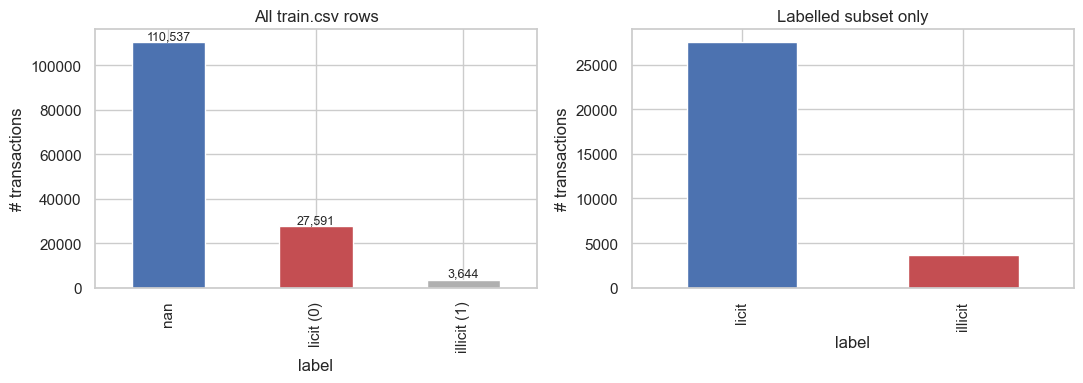

In [ ]:
# Visualize the label distribution in train.csv, both including and excluding the unlabelled rows
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Full breakdown including unknown
label_dist["count"].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52", "#B0B0B0"])
axes[0].set_title("All train.csv rows")
axes[0].set_ylabel("# transactions")
for i, v in enumerate(label_dist["count"]):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

# Labelled-only view
labelled["label"].map({0: "licit", 1: "illicit"}).value_counts().plot(
    kind="bar", ax=axes[1], color=["#4C72B0", "#C44E52"]
)
axes[1].set_title("Labelled subset only")
axes[1].set_ylabel("# transactions")

plt.tight_layout()
plt.show()

### 3.2 Label Distribution Over Time

In [15]:
by_step = (
    labelled.groupby("time_step")["label"]
    .agg(n_labelled="count", n_illicit="sum")
    .assign(
        n_licit=lambda d: d["n_labelled"] - d["n_illicit"],
        illicit_rate=lambda d: d["n_illicit"] / d["n_labelled"] * 100,
    )
)
by_step

,n_labelled,n_illicit,n_licit,illicit_rate
time_step,,,,
1,2147,17,2130,0.791803
2,1117,18,1099,1.611459
3,1279,11,1268,0.860047
4,1440,30,1410,2.083333
5,1882,8,1874,0.425080
6,485,5,480,1.030928
7,1203,102,1101,8.478803
8,1165,67,1098,5.751073
9,778,248,530,31.876607


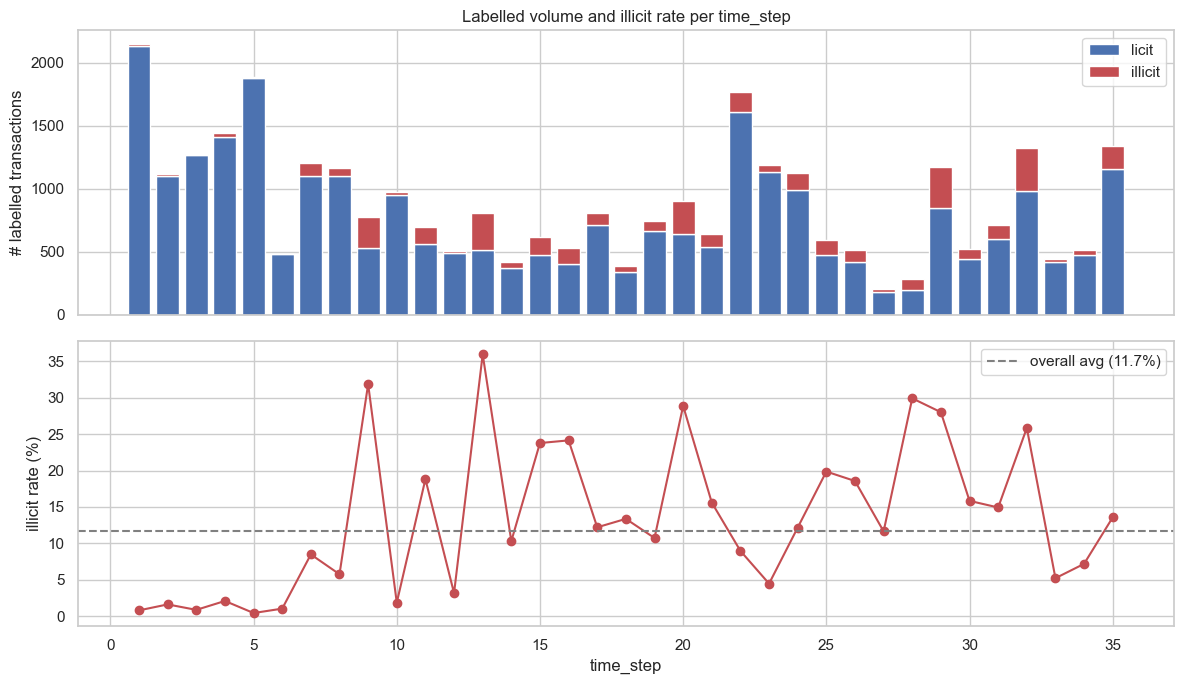

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].bar(by_step.index, by_step["n_licit"], label="licit", color="#4C72B0")
axes[0].bar(by_step.index, by_step["n_illicit"], bottom=by_step["n_licit"], label="illicit", color="#C44E52")
axes[0].set_ylabel("# labelled transactions")
axes[0].set_title("Labelled volume and illicit rate per time_step")
axes[0].legend()

axes[1].plot(by_step.index, by_step["illicit_rate"], marker="o", color="#C44E52")
axes[1].axhline(illicit_rate := n_illicit/len(labelled)*100, color="gray", linestyle="--", label=f"overall avg ({illicit_rate:.1f}%)")
axes[1].set_ylabel("illicit rate (%)")
axes[1].set_xlabel("time_step")
axes[1].legend()

plt.tight_layout()
plt.show()

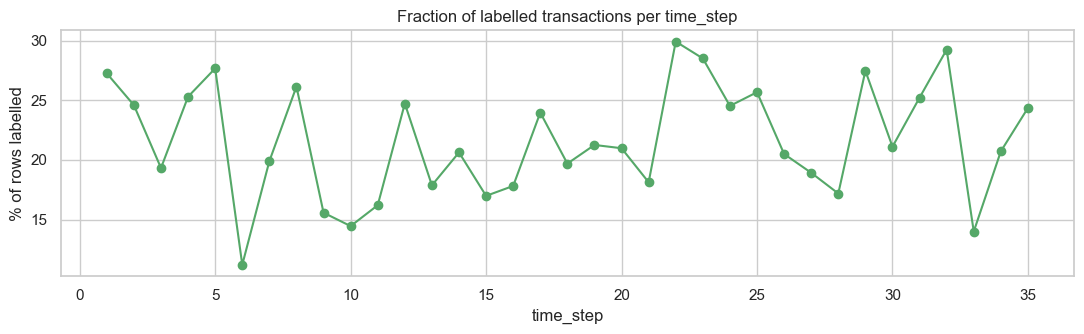

In [17]:
labelled_frac_by_step = (
    train.groupby("time_step")["label"]
    .apply(lambda s: s.notna().mean() * 100)
    .rename("pct_labelled")
)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(labelled_frac_by_step.index, labelled_frac_by_step.values, marker="o", color="#55A868")
ax.set_ylabel("% of rows labelled")
ax.set_xlabel("time_step")
ax.set_title("Fraction of labelled transactions per time_step")
plt.tight_layout()
plt.show()

In [18]:
# Check if illicit ratio changes if expanding time windows are used
by_step_sorted = by_step.sort_index()
cum_illicit = by_step_sorted["n_illicit"].cumsum()
cum_licit = by_step_sorted["n_licit"].cumsum()
cum_ratio = (cum_licit / cum_illicit).rename("cumulative_licit_to_illicit_ratio")

for fold_end in [20, 25, 30, 35]:
    print(f"train 1-{fold_end}: ratio = {cum_ratio.loc[fold_end]:.2f}")

train 1-20: ratio = 9.67
train 1-25: ratio = 9.36
train 1-30: ratio = 8.11
train 1-35: ratio = 7.57


### 3.3 Checking for Bias in Labelling Process

Correlation between illicit rate and % labelled per time_step: -0.165


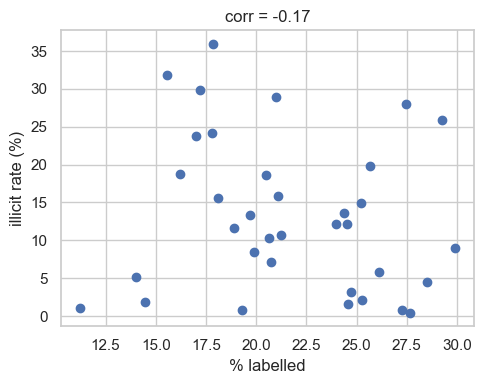

In [19]:
# Check correlation between illicit rate and % labelled per time_step
corr = by_step["illicit_rate"].corr(labelled_frac_by_step.reindex(by_step.index))
print(f"Correlation between illicit rate and % labelled per time_step: {corr:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(labelled_frac_by_step.reindex(by_step.index), by_step["illicit_rate"], color="#4C72B0")
ax.set_xlabel("% labelled")
ax.set_ylabel("illicit rate (%)")
ax.set_title(f"corr = {corr:.2f}")
plt.tight_layout()
plt.show()

### 3.4 Transaction Volume Over Time

In [20]:
volume_by_step = train.groupby("time_step").size().rename("n_transactions")
volume_by_step

time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
Name: n_transactions, dtype: int64

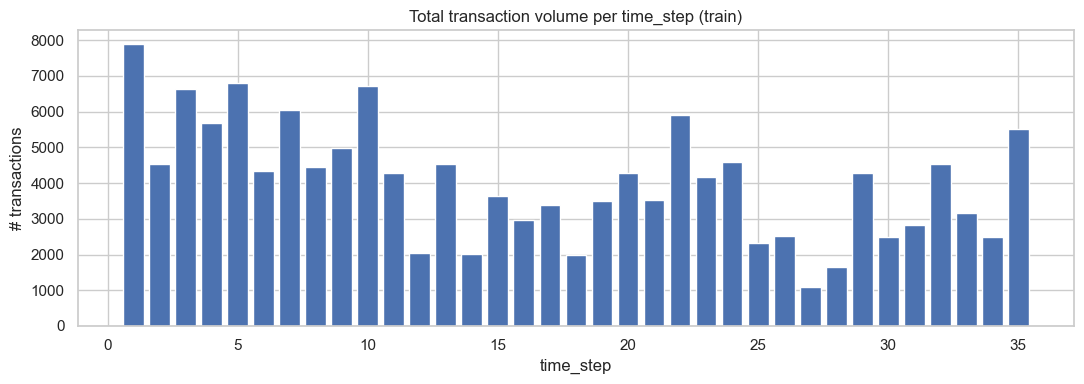

In [21]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(volume_by_step.index, volume_by_step.values, color="#4C72B0")
ax.set_xlabel("time_step")
ax.set_ylabel("# transactions")
ax.set_title("Total transaction volume per time_step (train)")
plt.tight_layout()
plt.show()

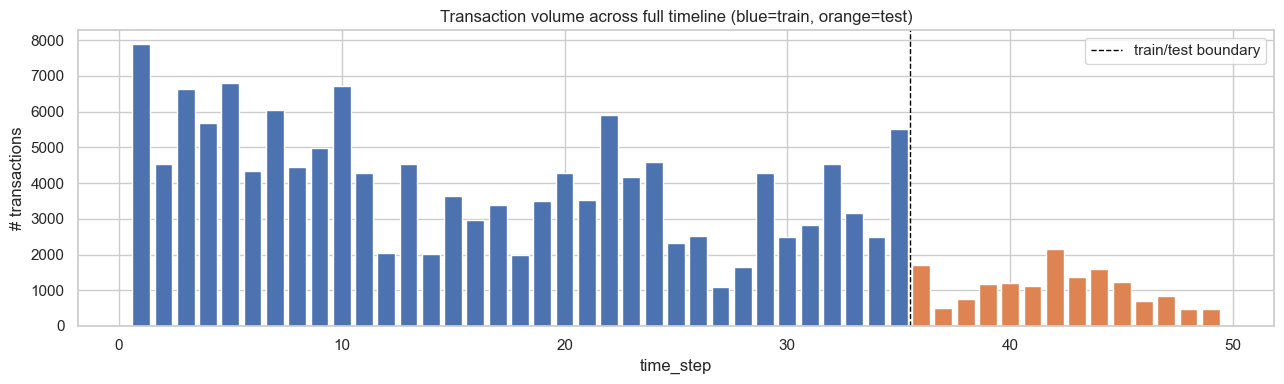

In [22]:
# Train and test together
test_volume_by_step = test.groupby("time_step").size().rename("n_transactions")

full_volume = pd.concat([
    volume_by_step.to_frame().assign(split="train"),
    test_volume_by_step.to_frame().assign(split="test"),
])

fig, ax = plt.subplots(figsize=(13, 4))
colors = full_volume["split"].map({"train": "#4C72B0", "test": "#DD8452"})
ax.bar(full_volume.index, full_volume["n_transactions"], color=colors)
ax.axvline(35.5, color="black", linestyle="--", linewidth=1, label="train/test boundary")
ax.set_xlabel("time_step")
ax.set_ylabel("# transactions")
ax.set_title("Transaction volume across full timeline (blue=train, orange=test)")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
print(f"train volume per step: mean={volume_by_step.mean():.0f}, std={volume_by_step.std():.0f}, "
      f"min={volume_by_step.min()}, max={volume_by_step.max()}")
print(f"test volume per step:  mean={test_volume_by_step.mean():.0f}, std={test_volume_by_step.std():.0f}, "
      f"min={test_volume_by_step.min()}, max={test_volume_by_step.max()}")

# Is there a directional trend (growing/shrinking network activity) across train?
trend_corr = np.corrcoef(volume_by_step.index, volume_by_step.values)[0, 1]
print(f"\nCorrelation between time_step and volume (train): {trend_corr:.3f}")

train volume per step: mean=4051, std=1648, min=1089, max=7880
test volume per step:  mean=1095, std=505, min=471, max=2154

Correlation between time_step and volume (train): -0.548


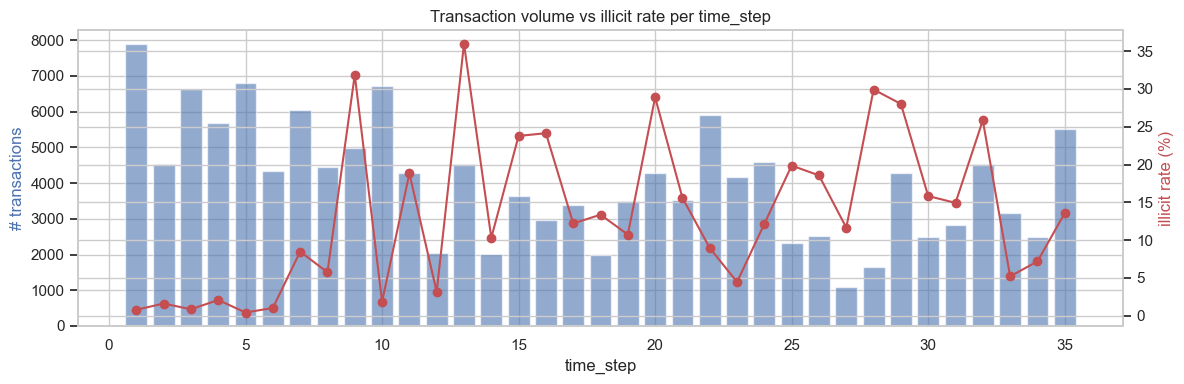

In [24]:
#Checking if volume coincides with illicit rate
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(volume_by_step.index, volume_by_step.values, color="#4C72B0", alpha=0.6, label="volume")
ax1.set_ylabel("# transactions", color="#4C72B0")
ax1.set_xlabel("time_step")

ax2 = ax1.twinx()
ax2.plot(by_step.index, by_step["illicit_rate"], color="#C44E52", marker="o", label="illicit rate (%)")
ax2.set_ylabel("illicit rate (%)", color="#C44E52")

ax1.set_title("Transaction volume vs illicit rate per time_step")
plt.tight_layout()
plt.show()

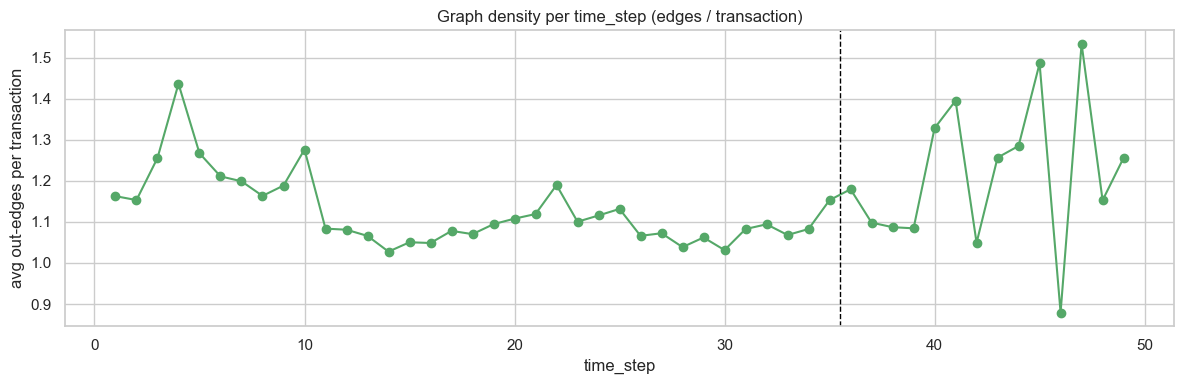

In [26]:
# Checking if edge count/connectivity of the graph chanegs over time
tx_to_step = pd.concat([
    train[["txId", "time_step"]], test[["txId", "time_step"]]
]).drop_duplicates("txId").set_index("txId")["time_step"]

edges_with_step = edges.assign(src_step=edges["txId1"].map(tx_to_step))
edges_per_step = edges_with_step.groupby("src_step").size().rename("n_edges")
avg_degree_per_step = edges_per_step / full_volume["n_transactions"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(avg_degree_per_step.index, avg_degree_per_step.values, marker="o", color="#55A868")
ax.axvline(35.5, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("time_step")
ax.set_ylabel("avg out-edges per transaction")
ax.set_title("Graph density per time_step (edges / transaction)")
plt.tight_layout()
plt.show()

## 4. Feature Analysis (165 Anonymized, Pre-Normalized Features)

### 4.1 Summary Statistics
**Section Findings:** 
- No near-zero-variance features.
- A subset of features show extreme skew and kurtosis, with ranges up to ~66,000 despite std ≈ 1.
- feat_38/feat_39 are the one case of symmetric-but-heavy-tailed (low skew, high kurtosis) caught by the kurtosis check.

**Follow Up Decisions:**
- No transform needed for tree-based models; documented as a data characteristic; will be revisited if attempting Logistic Regression/GNN.

In [27]:
feat_stats = train[feature_cols].describe().T  # count, mean, std, min, 25%, 50%, 75%, max
feat_stats["skew"] = train[feature_cols].skew()
feat_stats["kurtosis"] = train[feature_cols].kurtosis()
feat_stats["range"] = feat_stats["max"] - feat_stats["min"]
feat_stats["abs_skew"] = feat_stats["skew"].abs()
feat_stats["near_zero_var"] = feat_stats["std"] < 1e-6

feat_stats.head()

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,range,abs_skew,near_zero_var
feat_1,141772.0,0.018390,1.119660,-0.172983,-0.172436,-0.168768,-0.135555,71.681966,25.954660,1061.777238,71.854948,25.954660,False
feat_2,141772.0,-0.108169,0.395017,-0.210553,-0.184668,-0.158783,-0.107012,25.674475,28.587131,1202.386197,25.885028,28.587131,False
feat_3,141772.0,-0.300165,0.961251,-1.756361,-1.201369,-0.646376,0.463609,2.128587,0.331866,-1.557998,3.884949,0.331866,False
feat_4,141772.0,-0.002866,0.990140,-0.121970,-0.121970,-0.121970,-0.046932,49.027598,26.441312,893.155904,49.149568,26.441312,False
feat_5,141772.0,0.000438,1.113030,-0.063725,-0.043875,-0.043875,-0.043875,260.090707,121.239663,23235.205495,260.154432,121.239663,False


In [29]:
print("Most skewed features:") # Skew matters for non-tree models (Logistic Regression, GNN) where a few extreme values can dominate the loss; tree models handle skew natively (they split on rank/threshold, not magnitude); informational for now
display(feat_stats.sort_values("abs_skew", ascending=False).head(10))

print("\nWidest range features:")
display(feat_stats.sort_values("range", ascending=False).head(10))

n_near_zero = feat_stats["near_zero_var"].sum()
print(f"\nNear-zero-variance features: {n_near_zero} / {len(feature_cols)}")
if n_near_zero > 0:
    display(feat_stats[feat_stats["near_zero_var"]])

# Features with high kurtosis but low skew -- symmetric heavy-tailed outliers
# that a skew-only check would miss.
hidden_outliers = feat_stats[(feat_stats["abs_skew"] < 0.5) & (feat_stats["kurtosis"] > 10)]
print(f"Symmetric but heavy-tailed features (missed by skew check alone): {len(hidden_outliers)}")
hidden_outliers[["skew", "kurtosis", "std", "range"]]

Most skewed features:


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,range,abs_skew,near_zero_var
feat_34,141772.0,-0.010303,1.117841,-0.024669,-0.024669,-0.024669,-0.024669,287.891515,241.507494,62076.147837,287.916184,241.507494,False
feat_36,141772.0,-0.009429,0.939680,-0.023045,-0.023045,-0.023045,-0.023045,289.204388,230.982966,66090.124527,289.227433,230.982966,False
feat_37,141772.0,-0.010464,1.119853,-0.026215,-0.026215,-0.026215,-0.026215,280.566222,226.713202,55965.487158,280.592436,226.713202,False
feat_35,141772.0,-0.014665,1.090815,-0.031272,-0.031272,-0.031272,-0.031272,269.701184,220.207320,53341.231611,269.732456,220.207320,False
feat_73,141772.0,-0.005105,0.787270,-0.015071,-0.015071,-0.015071,-0.015071,151.035179,158.242598,28069.650983,151.050250,158.242598,False
feat_72,141772.0,-0.007739,0.763021,-0.017640,-0.017640,-0.017640,-0.017640,146.472930,153.672357,26535.469919,146.490570,153.672357,False
feat_71,141772.0,-0.015487,0.764980,-0.030026,-0.030026,-0.030026,-0.030026,137.851862,140.100498,23374.885390,137.881888,140.100498,False
feat_14,141772.0,0.000478,1.117975,-0.063200,-0.042955,-0.042955,-0.042955,265.263236,126.387082,24688.917521,265.326436,126.387082,False
feat_162,141772.0,-0.044833,1.038040,-0.131155,-0.131155,-0.131155,-0.084674,238.783493,122.823848,23356.140322,238.914648,122.823848,False
feat_5,141772.0,0.000438,1.113030,-0.063725,-0.043875,-0.043875,-0.043875,260.090707,121.239663,23235.205495,260.154432,121.239663,False



Widest range features:


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,range,abs_skew,near_zero_var
feat_36,141772.0,-0.009429,0.939680,-0.023045,-0.023045,-0.023045,-0.023045,289.204388,230.982966,66090.124527,289.227433,230.982966,False
feat_34,141772.0,-0.010303,1.117841,-0.024669,-0.024669,-0.024669,-0.024669,287.891515,241.507494,62076.147837,287.916184,241.507494,False
feat_37,141772.0,-0.010464,1.119853,-0.026215,-0.026215,-0.026215,-0.026215,280.566222,226.713202,55965.487158,280.592436,226.713202,False
feat_35,141772.0,-0.014665,1.090815,-0.031272,-0.031272,-0.031272,-0.031272,269.701184,220.207320,53341.231611,269.732456,220.207320,False
feat_14,141772.0,0.000478,1.117975,-0.063200,-0.042955,-0.042955,-0.042955,265.263236,126.387082,24688.917521,265.326436,126.387082,False
feat_5,141772.0,0.000438,1.113030,-0.063725,-0.043875,-0.043875,-0.043875,260.090707,121.239663,23235.205495,260.154432,121.239663,False
feat_161,141772.0,-0.022239,1.087520,-0.125939,-0.087490,-0.087490,-0.087490,251.849028,116.576771,22349.829309,251.974967,116.576771,False
feat_162,141772.0,-0.044833,1.038040,-0.131155,-0.131155,-0.131155,-0.084674,238.783493,122.823848,23356.140322,238.914648,122.823848,False
feat_130,141772.0,0.002088,1.097451,-0.124895,-0.124373,-0.121608,-0.098959,224.458675,114.813344,20613.418700,224.583570,114.813344,False
feat_10,141772.0,-0.000565,0.894260,-0.049707,-0.049707,-0.049707,-0.049707,189.186944,94.369339,15670.517694,189.236651,94.369339,False



Near-zero-variance features: 0 / 165
Symmetric but heavy-tailed features (missed by skew check alone): 2


,skew,kurtosis,std,range
feat_38,0.190659,34.742726,1.108780,13.996067
feat_39,0.190906,34.698248,1.109207,13.994992


### 4.2 Class Separation by Feature
Check if individual features carry signal about the label

**Section Findings:**
- Only 5 features individually exceed AUC 0.70, 18 exceed 0.60; no single dominant feature; most signal will come from combinations, favoring ensemble/tree methods over linear models.
- Most top-separating features have AUC below 0.5 (e.g. feat_53=0.14, feat_55=0.16, feat_90=0.16), meaning low values signal illicit for most of them, the inverse direction. feat_142 (AUC 0.80) is the one notable exception pointing the opposite way (high value = illicit).

**Follow Up Decisions:**
- Direction will be stated explictly when discussing top features

In [30]:
from sklearn.metrics import roc_auc_score

y_true = labelled["label"].values
single_feat_auc = {c: roc_auc_score(y_true, labelled[c]) for c in feature_cols}

separation = pd.DataFrame({"single_feature_auc": pd.Series(single_feat_auc)})
separation["dist_from_0.5"] = (separation["single_feature_auc"] - 0.5).abs()
separation = separation.sort_values("dist_from_0.5", ascending=False)

print(f"# features with single-feature AUC > 0.70: {(separation['single_feature_auc'] > 0.70).sum()}")
print(f"# features with single-feature AUC > 0.60: {(separation['single_feature_auc'] > 0.60).sum()}")
separation.head(15)

# features with single-feature AUC > 0.70: 5
# features with single-feature AUC > 0.60: 18


,single_feature_auc,dist_from_0.5
feat_53,0.143191,0.356809
feat_55,0.160340,0.339660
feat_90,0.163298,0.336702
feat_5,0.182999,0.317001
feat_14,0.183078,0.316922
feat_66,0.183595,0.316405
feat_60,0.183608,0.316392
feat_29,0.186834,0.313166
feat_23,0.186841,0.313159
feat_132,0.189213,0.310787


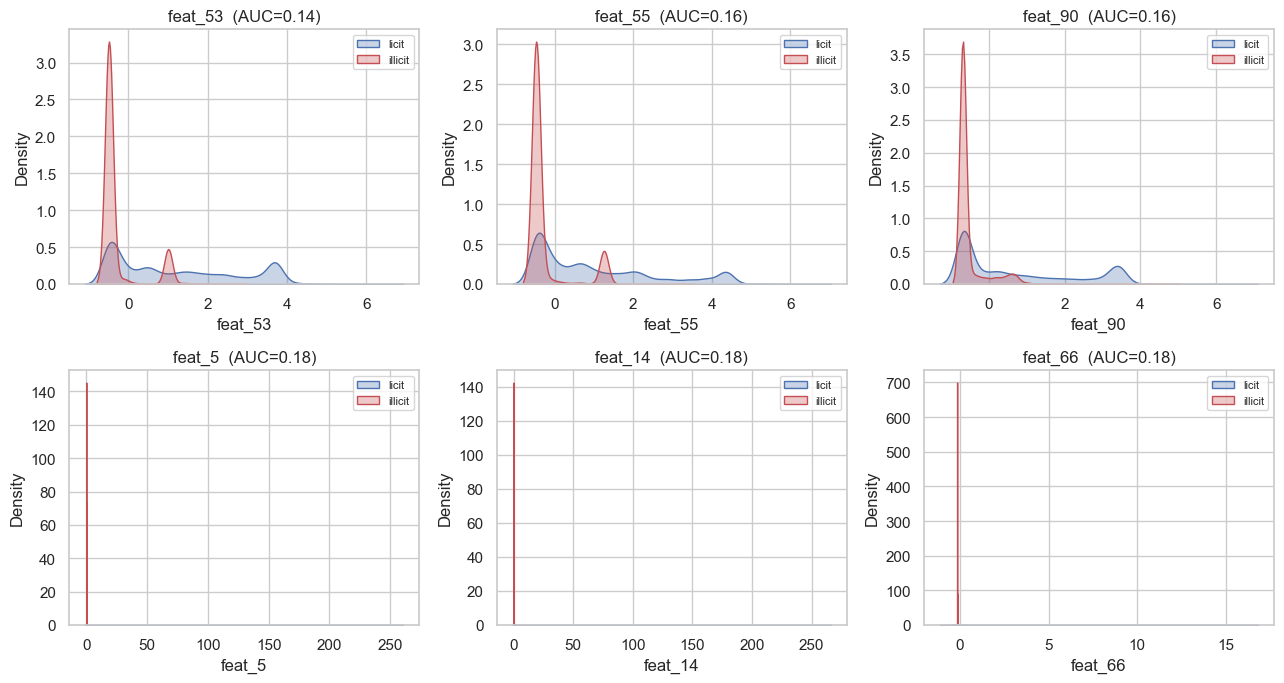

In [31]:
licit_vals = labelled[labelled.label == 0][feature_cols]
illicit_vals = labelled[labelled.label == 1][feature_cols]
top_feats = separation.index[:6]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feat in zip(axes.flat, top_feats):
    sns.kdeplot(licit_vals[feat], ax=ax, label="licit", color="#4C72B0", fill=True, alpha=0.3)
    sns.kdeplot(illicit_vals[feat], ax=ax, label="illicit", color="#C44E52", fill=True, alpha=0.3)
    ax.set_title(f"{feat}  (AUC={separation.loc[feat, 'single_feature_auc']:.2f})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.3 Redundancy & Correlation Check
**Section Findings:**
- 95 feature pairs exceed |corr| = 0.95; 94/165 features (57%) are involved in at least one such pair. 8 pairs are exactly correlated (corr = 1.000000).

**Follow Up Decisions:**
- Drop one column from each exact-duplicate pair (zero information loss, free cleanup). Leave the 0.95–0.999 pairs alone as tree models handle near-duplicates fine, and they're documented rather than acted on. To revisit pruning or other measures of dimensionality reduction e.g. PCA if doing Logistic Regresion or GNN later on
- Effective feature count is meaningfully smaller than 165; should rely on tree-model regularization over manual feature elimination as the primary overfitting defense, revisited only if CV shows a large train/val gap.

In [32]:
sample_for_corr = train[feature_cols].sample(n=min(20000, len(train)), random_state=RANDOM_STATE)
corr = sample_for_corr.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack().reset_index()
    .rename(columns={"level_0": "feat_a", "level_1": "feat_b", 0: "abs_corr"})
    .query("abs_corr > 0.95")
    .sort_values("abs_corr", ascending=False)
)
print(f"# feature pairs with |corr| > 0.95: {len(high_corr_pairs)}")
high_corr_pairs.head(20)

# feature pairs with |corr| > 0.95: 95


,feat_a,feat_b,abs_corr
9800,feat_60,feat_66,1.000000
9966,feat_61,feat_67,1.000000
3824,feat_24,feat_30,1.000000
9634,feat_59,feat_65,1.000000
3658,feat_23,feat_29,1.000000
3990,feat_25,feat_31,1.000000
3492,feat_22,feat_28,1.000000
9468,feat_58,feat_64,1.000000
4322,feat_27,feat_33,0.999998
4156,feat_26,feat_32,0.999996


In [33]:
correlated_feats = set(high_corr_pairs["feat_a"]) | set(high_corr_pairs["feat_b"])
print(f"# features involved in at least one >0.95 correlated pair: {len(correlated_feats)} / {len(feature_cols)}")
print(f"# features with no near-duplicate: {len(feature_cols) - len(correlated_feats)}")

# features involved in at least one >0.95 correlated pair: 94 / 165
# features with no near-duplicate: 71


### 4.4 Adversarial Validation to Check Temporal Drift
**Section Findings:**
- Adversarial AUC = 1.000: train and test are perfectly distinguishable from features alone.
- Drift is concentrated in importance, but not fixable by removal: feat_103 (0.176), feat_101 (0.152), feat_136 (0.141), feat_100 (0.133), feat_139 (0.111), feat_137 (0.056) together account for ~77% of the adversarial model's feature importance. Visualized distributions confirm near-total non-overlap between train/test for feat_103/feat_101/feat_136. But removing those 6 features only dropped adversarial AUC to 0.944, proving the drift is pervasive across most of the 165 features, not isolated to a handful of "bad" columns.
- Overlap between top-20 separating features and top-20 drifting features: only feat_142; features that make the model work and the features causing the drift are almost entirely disjoint.

**Follow Up Decisions:**
- Test if dropping the top-6 drift-features to check whether adversarial AUC falls while real validation AUC holds
- Flag feat_142 specifically as high-value-but-unstable, since it's the one feature that's both predictive and drifting;
- Document that this drift may partly reflect the legitimate volume decline found earlier, not necessarily a data defect.


In [34]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

adv_df = pd.concat([
    train[feature_cols].assign(is_test=0),
    test[feature_cols].assign(is_test=1),
])
X_adv, y_adv = adv_df[feature_cols], adv_df["is_test"]

adv_clf = RandomForestClassifier(n_estimators=200, max_depth=6, n_jobs=-1, random_state=RANDOM_STATE)
adv_auc = cross_val_score(adv_clf, X_adv, y_adv, cv=3, scoring="roc_auc").mean()
print(f"Adversarial validation AUC (train vs test): {adv_auc:.3f}")

Adversarial validation AUC (train vs test): 1.000


In [35]:
# If AUC is meaningfully above 0.5, find which features drive the separation --
# those are the features most likely to hurt generalization and worth extra scrutiny.
adv_clf.fit(X_adv, y_adv)
top_drift_feats = pd.Series(adv_clf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
top_drift_feats

feat_103    0.175711
feat_101    0.151855
feat_136    0.141186
feat_100    0.133273
feat_139    0.111350
feat_137    0.055696
feat_2      0.029194
feat_109    0.023706
feat_113    0.020100
feat_107    0.020075
feat_106    0.017229
feat_115    0.013814
feat_142    0.010193
feat_3      0.008075
feat_138    0.005217
dtype: float64

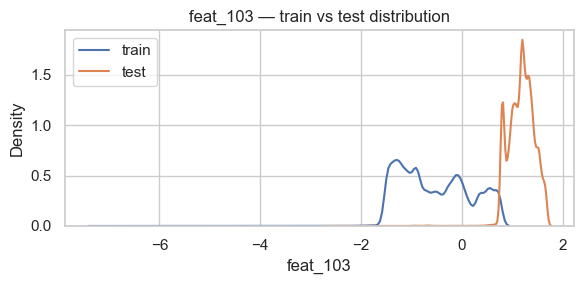

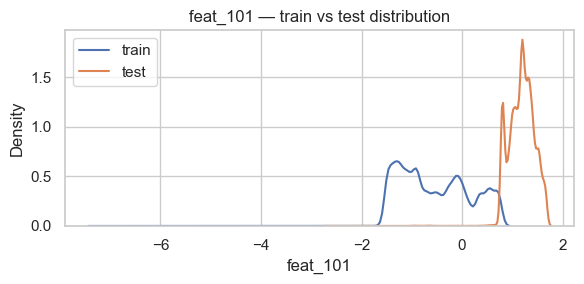

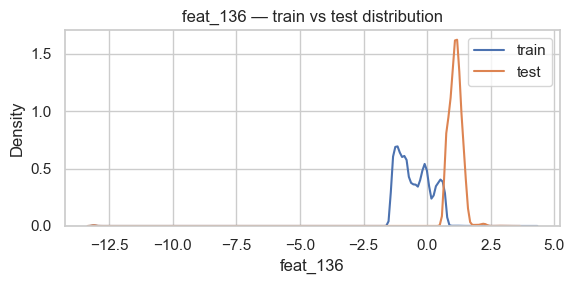

In [ ]:
for feat in top_drift_feats.index[:3]:
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.kdeplot(train[feat], label="train", ax=ax, color="#4C72B0")
    sns.kdeplot(test[feat], label="test", ax=ax, color="#DD8452")
    ax.set_title(f"{feat} — train vs test distribution")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [37]:
top_separating_set = set(separation.index[:20])
top_drift_set = set(top_drift_feats.index[:20])
overlap = top_separating_set & top_drift_set
print(f"Features in both top-20 separating AND top-20 drifting: {len(overlap)}")
print(overlap)

Features in both top-20 separating AND top-20 drifting: 1
{'feat_142'}


In [38]:
# Test when top drifting features dropped
drift_cols_to_test = ["feat_100", "feat_101", "feat_103", "feat_136", "feat_137", "feat_139"]
reduced_feature_cols = [c for c in feature_cols if c not in drift_cols_to_test]

X_adv_reduced = adv_df[reduced_feature_cols]
adv_auc_reduced = cross_val_score(adv_clf, X_adv_reduced, y_adv, cv=3, scoring="roc_auc").mean()
print(f"Adversarial AUC after dropping top-6 drift features: {adv_auc_reduced:.3f}  (was 1.000)")

Adversarial AUC after dropping top-6 drift features: 0.944  (was 1.000)


## 5. Graph EDA


### 5.1 Graph Structure & Degree Analysis

**Section findings:**
- Graph is clean and complete, with 0 duplicate edges, 0 self-loops, and 0 isolated transactions
- Degree is heavily right-skewed, as expected: median total_degree = 2, but max reaches 473; consistent with the brief's note about exchange sweeps/payouts producing high-degree hub transactions. Visual checks confirms a spike near 0, followed by a right tail. In-degree has a noticeably fatter, more gradual tail, decaying smoothly rather than collapsing immediately. Out-degree, by contrast, drops off much more sharply after the initial spike, falling to single-digit counts with only a couple of isolated extreme outliers way out past 250 and 470.
- Hub transactions reveal a pattern: licit hubs tend to distribute (high out-degree) while illicit hubs tend to aggregate (high in-degree with near-zero out-degree transactions); consistent with mixing/consolidating funds from many small illicit inputs into one transaction. 
- Illicit transactions essentially never have meaningful out-degree, as the max across all ~3,644 illicit transactions is 2, and the 99th percentile is also 2. Licit transactions, by contrast, have a real tail: 99th percentile = 5, max = 472. This means high out-degree (fan-out to many recipients) is, in this dataset, close to an exclusively licit signature. For in-degree, illicit cases have a lower mean (1.25 vs. 1.83) and lower percentiles at every level up to the 99th (illicit 99th percentile = 4 vs. licit's 23). Hence, the typical illicit transaction is low-in-degree, even lower than typical licit. But illicit's std is actually higher (7.23 vs. licit's 6.12) despite the lower mean, and its max still reaches 173. This combination of low typical value, high variance, and substantial max points to illicit transactions being a mix of two behaviors: the bulk are low-connectivity "quick-move" transactions, while a small subset act as extreme in-degree aggregators (consistent with the illicit hub transactions found). Licit's distribution is more evenly graded by comparison, without as sharp a small-subgroup deviation.
- Degree remains distinct from existing features: max correlation still feat_6 at 0.459, which is moderate and not remotely close to a near-duplicate. Suggesting that degree features add genuinely new information rather than re-deriving something already present in the existing features.

**Follow Up Decisions:**
- In-degree and out-degree should be kept separate as features, not just combined into total_degree.
- Consider adding a threshold/flag feature for out-degree, e.g. out_degree > 2, which will behave like a binary indicator that will be a strong licit signal. Suitable for tree models.
- Consider a log or rank transform for in_degree specifically (not necessarily out_degree, given its near-ceiling behavior for illicit), as its bimodal, heavy-tailed shape (mostly 0-4, occasional aggregator up to 173) distribution benefits from compressing the tail so the model doesn't treat a jump from 4→170 as proportionally as extreme as the raw values suggest.

In [39]:
G = nx.from_pandas_edgelist(edges, source="txId1", target="txId2", create_using=nx.DiGraph())
print(f"Graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")

print("Is DAG (no cycles):", nx.is_directed_acyclic_graph(G))

all_tx_ids = pd.concat([train["txId"], test["txId"]]).unique()
coverage = len(set(all_tx_ids) & set(G.nodes())) / len(all_tx_ids) * 100
print(f"% of train+test txIds present in the graph: {coverage:.1f}%")

# Duplicate edges / self-loops (recap from data quality)
print("Duplicate edges:", edges.duplicated().sum())
print("Self-loops:", (edges["txId1"] == edges["txId2"]).sum())

Graph: 203,769 nodes, 234,355 edges
Is DAG (no cycles): True
% of train+test txIds present in the graph: 100.0%
Duplicate edges: 0
Self-loops: 0


In [40]:
in_deg = pd.Series(dict(G.in_degree()), name="in_degree")
out_deg = pd.Series(dict(G.out_degree()), name="out_degree")
deg_df = pd.concat([in_deg, out_deg], axis=1).fillna(0).astype(int)
deg_df["total_degree"] = deg_df["in_degree"] + deg_df["out_degree"]

deg_df.describe()

,in_degree,out_degree,total_degree
count,203769.000000,203769.000000,203769.000000
mean,1.150101,1.150101,2.300203
std,3.911132,1.894740,4.328377
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000


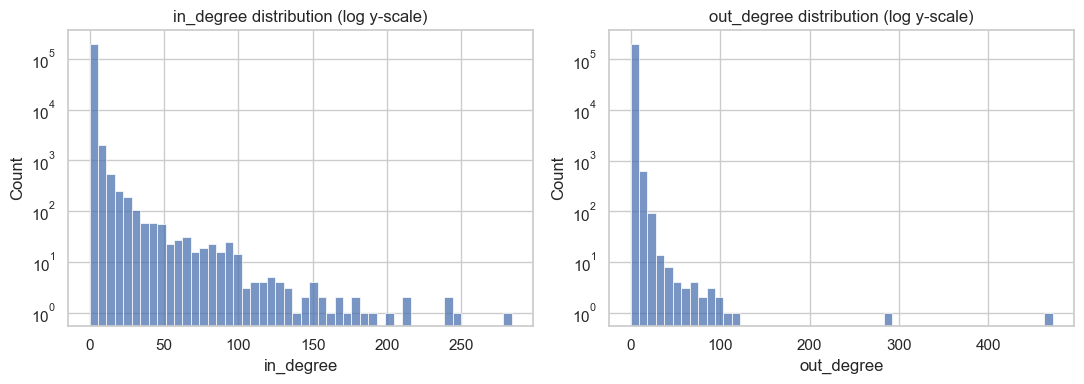

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["in_degree", "out_degree"]):
    sns.histplot(deg_df[col], bins=50, ax=ax, color="#4C72B0")
    ax.set_yscale("log")
    ax.set_title(f"{col} distribution (log y-scale)")
plt.tight_layout()
plt.show()

In [42]:
# Top-20 highest-degree "hub" transactions -- are they labelled, and if so, which class?
top_hubs = deg_df.sort_values("total_degree", ascending=False).head(20)
top_hubs = top_hubs.join(train.set_index("txId")["label"], how="left")
top_hubs

,in_degree,out_degree,total_degree,label
2984918,1,472,473,0.0
89273,1,288,289,0.0
43388675,284,0,284,0.0
68705820,247,0,247,0.0
30699343,241,0,241,NaN
96576418,239,0,239,0.0
225859042,212,0,212,NaN
279187194,211,0,211,0.0
234890810,199,0,199,NaN
196107869,188,0,188,NaN


In [45]:
# Check isolated tansactions/nodes
isolated_tx_ids = set(all_tx_ids) - set(G.nodes())
print(f"# isolated transactions (no edges at all): {len(isolated_tx_ids):,} "
      f"({len(isolated_tx_ids)/len(all_tx_ids)*100:.2f}% of train+test)")

# isolated transactions (no edges at all): 0 (0.00% of train+test)


In [46]:
# Checking degree by label

# Merge degree onto labelled transactions
labelled_with_deg = labelled.merge(deg_df, left_on="txId", right_index=True, how="left")
labelled_with_deg[["in_degree", "out_degree", "total_degree"]] = labelled_with_deg[
    ["in_degree", "out_degree", "total_degree"]
].fillna(0)

deg_by_label = labelled_with_deg.groupby("label")[["in_degree", "out_degree", "total_degree"]].median()
deg_by_label.index = deg_by_label.index.map({0: "licit", 1: "illicit"})
deg_by_label

,in_degree,out_degree,total_degree
label,,,
licit,1.0,1.0,2.0
illicit,1.0,1.0,1.0


In [52]:
degree_by_label_full = labelled_with_deg.groupby("label")[["in_degree", "out_degree", "total_degree"]].agg(
    ["mean", "median", "std", "max"]
)
degree_by_label_full.index = degree_by_label_full.index.map({0: "licit", 1: "illicit"})
degree_by_label_full

in_degree                       out_degree                       total_degree                      
             mean median       std  max       mean median       std  max         mean median       std  max
label                                                                                                      
licit    1.830379    1.0  6.115934  284   1.148382    1.0  3.781589  472     2.978761    2.0  7.085993  473
illicit  1.254391    1.0  7.225918  173   0.754665    1.0  0.555132    2     2.009056    1.0  7.189385  173

In [53]:
# Percentiles get past the 0/1/2 plateau that the median gets stuck on
percentile_by_label = labelled_with_deg.groupby("label")[["in_degree", "out_degree", "total_degree"]].quantile(
    [0.5, 0.75, 0.9, 0.95, 0.99]
)
percentile_by_label

in_degree  out_degree  total_degree
label                                          
0     0.50        1.0         1.0           2.0
      0.75        1.0         1.0           3.0
      0.90        3.0         2.0           4.0
      0.95        6.0         2.0           8.0
      0.99       23.0         5.0          24.0
1     0.50        1.0         1.0           1.0
      0.75        1.0         1.0           2.0
      0.90        1.0         1.0           2.0
      0.95        1.0         2.0           3.0
      0.99        4.0         2.0           5.0

In [48]:
# Does degree overlap with existing local features?
deg_feat_corr = train.merge(deg_df, left_on="txId", right_index=True, how="left")[feature_cols + ["total_degree"]]
deg_feat_corr = deg_feat_corr.fillna(0)
corr_with_degree = deg_feat_corr.corr()["total_degree"].drop("total_degree").abs().sort_values(ascending=False)
print("Top 10 existing features most correlated with total_degree:")
corr_with_degree.head(10)

Top 10 existing features most correlated with total_degree:


feat_6      0.458965
feat_4      0.448759
feat_2      0.355172
feat_14     0.312197
feat_5      0.308608
feat_119    0.154014
feat_114    0.135553
feat_120    0.092882
feat_54     0.080427
feat_82     0.077908
Name: total_degree, dtype: float64

### 5.2 Connected Components

**Section Findings:**
- Component count (49) exactly matches the total number of time_steps (35 train + 14 test = 49), suggesting that the graph essentially partitions into one connected component per time_step, with no bridging between them. Component sizes (min 1,089, max 7,880) closely track your earlier per-time_step transaction volume numbers. Among edges where both endpoints have a known time_step, 100% share the exact same time_step. The step_diff value_counts table shows only one value: 0.0, confirming the brief's claim that connected transactions belong to the same time_step.
- The largest component is only 3.9% of the whole graph i.e. no dominant "giant component", expected since the graph is fragmented by time_step.
- Zero edges cross the train/test boundary in either direction. Test transactions have no structural connection whatsoever to train transactions. Their neighborhoods are entirely self-contained within the test period.
- ~25% of edges reference a transaction that doesn't exist in either train.csv or test.csv, as it involves at least one txId with no time_step mapping. Further confirming this, the graph has 203,769 total nodes, but train+test together only account for 157,101 unique txIds. The unaccounted nodes are likely transactions from the broader underlying dataset that fall outside this specific train/test sample.

**Follow Up Decisions:**
- No need for features that assume connectivity spans across time periods.
- Any neighbor-aggregate features using the neighbor's other feature values (not just label) must explicitly filter to neighbors present in train/test, or ~25% of aggregations will silently produce NaN.

In [54]:
components = list(nx.weakly_connected_components(G))
component_sizes = pd.Series([len(c) for c in components]).sort_values(ascending=False)

print(f"# weakly connected components: {len(components):,}")
print(f"Largest component size: {component_sizes.iloc[0]:,} ({component_sizes.iloc[0]/G.number_of_nodes()*100:.1f}% of graph)")
component_sizes.describe()

# weakly connected components: 49
Largest component size: 7,880 (3.9% of graph)


count      49.000000
mean     4158.551020
std      1592.470592
min      1089.000000
25%      2891.000000
50%      4291.000000
75%      5121.000000
max      7880.000000
dtype: float64

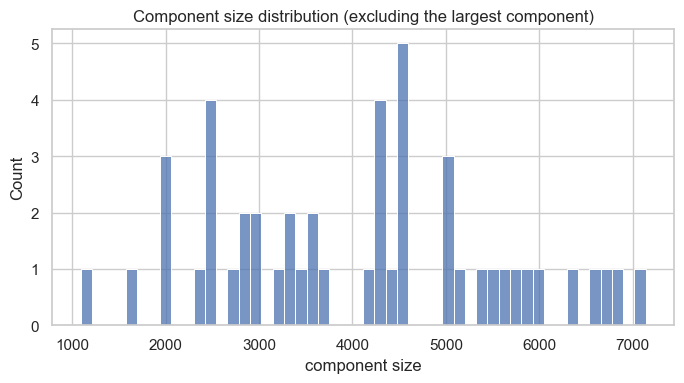

In [55]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(component_sizes[component_sizes < component_sizes.iloc[0]], bins=50, ax=ax, color="#4C72B0")
ax.set_title("Component size distribution (excluding the largest component)")
ax.set_xlabel("component size")
plt.tight_layout()
plt.show()

In [56]:
# Checking if connected transactions share the same time_step
tx_to_step = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId")["time_step"]

edges_steps = edges.assign(
    step1=edges["txId1"].map(tx_to_step),
    step2=edges["txId2"].map(tx_to_step),
)
edges_steps["step_diff"] = edges_steps["step2"] - edges_steps["step1"]

print("Edge step_diff value counts:")
print(edges_steps["step_diff"].value_counts().sort_index())
print(f"\n% of edges with same time_step on both ends: {(edges_steps['step_diff']==0).mean()*100:.2f}%")

Edge step_diff value counts:
step_diff
0.0    175918
Name: count, dtype: int64

% of edges with same time_step on both ends: 75.06%


In [63]:
# Checking for phantom nodes -- transactions that appear in the edgelist but not in train/test
graph_ids = set(G.nodes())
known_ids = train_ids | test_ids
phantom_ids = graph_ids - known_ids

print(f"Nodes in graph: {len(graph_ids):,}")
print(f"Nodes in train+test: {len(known_ids):,}")
print(f"Phantom nodes (in edgelist, not in train/test): {len(phantom_ids):,} ({len(phantom_ids)/len(graph_ids)*100:.1f}%)")

Nodes in graph: 203,769
Nodes in train+test: 157,101
Phantom nodes (in edgelist, not in train/test): 46,668 (22.9%)


In [64]:
# how many phantom nodes fall in the largest component vs elsewhere?
largest_cc = max(components, key=len)
phantom_in_largest = len(phantom_ids & largest_cc)
print(f"Phantom nodes in largest component: {phantom_in_largest:,} / {len(largest_cc):,}")

Phantom nodes in largest component: 0 / 7,880


In [57]:
# Cross-boundary Connectivity
train_ids, test_ids = set(train["txId"]), set(test["txId"])

train_to_test_edges = edges[edges["txId1"].isin(train_ids) & edges["txId2"].isin(test_ids)]
test_to_train_edges = edges[edges["txId1"].isin(test_ids) & edges["txId2"].isin(train_ids)]

print(f"Edges from train -> test transactions: {len(train_to_test_edges):,}")
print(f"Edges from test -> train transactions (should be ~0, would violate forward-time ordering): {len(test_to_train_edges):,}")

Edges from train -> test transactions: 0
Edges from test -> train transactions (should be ~0, would violate forward-time ordering): 0


### 5.3 Neighbor Label Composition (Homophily Check)

**Section Findings:**
- Severe, unambiguous homophily: Illicit transactions' neighbors are, on average, 29.5% illicit, which is nearly 2.5x the overall illicit base rate (11.67%). Licit transactions' neighbors, by contrast, are only 1.77% illicit, which is below the base rate, meaning licit transactions cluster even more tightly among other licit transactions than random chance would suggest. The gap between the two groups (29.5% vs. 1.77%, roughly 16.7x) shows that illicit transactions are strongly clustered together in the graph, not scattered randomly among licit ones. A neighbor-illicit-fraction feature should be useful.
- Visual checks confirm that neighbour-illicit-fraction for licit cases is almost entirely concentrated at 0 (~97% of licit transactions have zero illicit neighbors), whereas for illicit its clearly bimodal. ~69% sit at 0 (no detected illicit neighbors), but a striking ~27% cluster right at 1.0 i.e. >1/4 of illicit transactions have neighbors that are entirely illicit. A handful more sit at intermediate fractional values (~0.5, ~0.65; almost certainly small-neighbor-count transactions like 1-of-2 or 2-of-3 neighbors being illicit).
- Methodological limitation: illicit_neighbor_frac = n_illicit / (n_illicit + n_licit + n_unknown); meaning a transaction whose neighbors are mostly unlabeled gets its fraction diluted toward 0, and transactions with zero labeled neighbors get NaN, which the later merge step silently filled to 0. Since most neighbor relationships in this graph point to unlabeled or phantom transactions (78% of train is unlabeled, all of test is unlabeled, and ~25% of edges hit phantom nodes entirely), this almost certainly means the observed homophily numbers understate the true effect, and the real underlying homophily is probably even stronger than 29.5%/1.77%.
- Hub-neighbor overlap is limited in scope. 4,165 transactions (2.65% of the population) are neighbors of the top-20 hubs, which is a real but contained group whose neighbor-aggregate features will be diluted by connection to one dominant, possibly atypical transaction.

**Follow Up Decisions:**
- Build illicit_neighbor_frac (and the underlying n_illicit_neighbors/n_licit_neighbors counts) as a feature.
- Build an explicit has_all_illicit_neighbors (or similar) binary flag in addition to the continuous illicit_neighbor_frac, capturing that 1.0 spike directly
- Refine the ratio to exclude unknowns from the denominator: use n_illicit / (n_illicit + n_licit), and add a separate n_known_neighbors (or has_known_neighbor flag) feature to distinguish "confirmed low illicit neighbors" from "no evidence available".
- Any neighbor-aggregate feature using neighbor feature values (not just label) must explicitly filter to neighbors present in train/test, since ~25% of edges touch phantom nodes with no feature row.
- Consider a robust aggregate or is_hub_neighbor flag for the 2.65% of transactions adjacent to extreme-degree hubs, since their neighbor-aggregate stats will behave differently from typical transactions.

In [58]:
# Build an undirected neighbor edge list (both directions) for efficient vectorized lookup
undirected_edges = pd.concat([
    edges.rename(columns={"txId1": "tx", "txId2": "neighbor"}),
    edges.rename(columns={"txId2": "tx", "txId1": "neighbor"}),
])

tx_label_map = train.set_index("txId")["label"]
undirected_edges["neighbor_label"] = undirected_edges["neighbor"].map(tx_label_map)

neighbor_summary = undirected_edges.groupby("tx")["neighbor_label"].agg(
    n_neighbors="count",
    n_illicit_neighbors=lambda s: (s == 1).sum(),
    n_licit_neighbors=lambda s: (s == 0).sum(),
    n_unknown_neighbors=lambda s: s.isna().sum(),
)
neighbor_summary["illicit_neighbor_frac"] = (
    neighbor_summary["n_illicit_neighbors"] / neighbor_summary["n_neighbors"]
)
neighbor_summary.head()

,n_neighbors,n_illicit_neighbors,n_licit_neighbors,n_unknown_neighbors,illicit_neighbor_frac
tx,,,,,
1076,0,0,0,2,NaN
2534,3,0,3,0,0.0
3181,113,0,113,0,0.0
3321,0,0,0,1,NaN
3889,0,0,0,50,NaN


In [59]:
labelled_with_neighbors = labelled.merge(neighbor_summary, left_on="txId", right_index=True, how="left")
labelled_with_neighbors["illicit_neighbor_frac"] = labelled_with_neighbors["illicit_neighbor_frac"].fillna(0)

homophily_check = labelled_with_neighbors.groupby("label")["illicit_neighbor_frac"].mean()
homophily_check.index = homophily_check.index.map({0: "licit", 1: "illicit"})
print("Average fraction of neighbors that are illicit, grouped by the transaction's own label:")
homophily_check

Average fraction of neighbors that are illicit, grouped by the transaction's own label:


label
licit      0.017697
illicit    0.295294
Name: illicit_neighbor_frac, dtype: float64

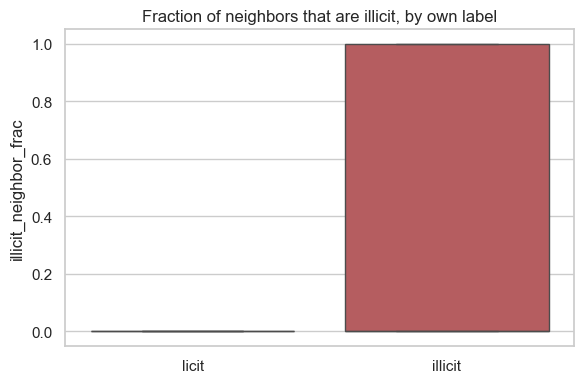

In [60]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    data=labelled_with_neighbors.assign(label_str=labelled_with_neighbors["label"].map({0: "licit", 1: "illicit"})),
    x="label_str", y="illicit_neighbor_frac", ax=ax, showfliers=False,
    palette={"licit": "#4C72B0", "illicit": "#C44E52"},
)
ax.set_title("Fraction of neighbors that are illicit, by own label")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

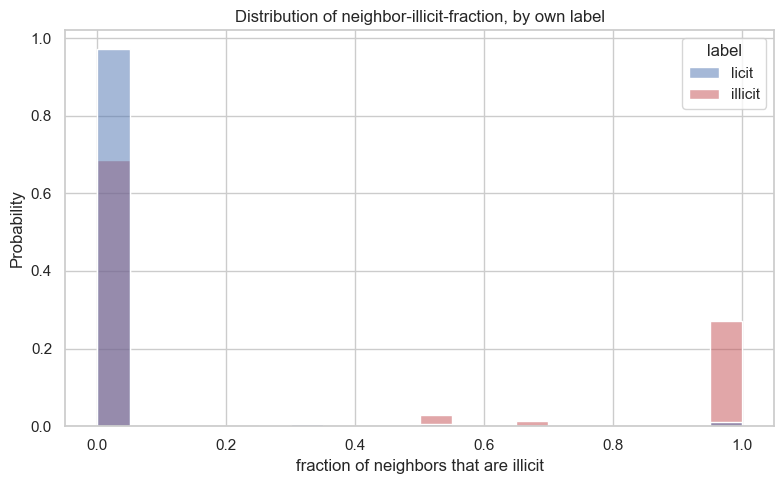

In [62]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(
    data=labelled_with_neighbors,
    x="illicit_neighbor_frac",
    hue=labelled_with_neighbors["label"].map({0: "licit", 1: "illicit"}),
    bins=20,
    stat="probability",
    common_norm=False,
    multiple="layer",
    alpha=0.5,
    palette={"licit": "#4C72B0", "illicit": "#C44E52"},
)
ax.set_title("Distribution of neighbor-illicit-fraction, by own label")
ax.set_xlabel("fraction of neighbors that are illicit")
plt.tight_layout()
plt.show()

In [61]:
# Hub Distortion Check: Are the top-20 highest-degree transactions (hubs) disproportionately illicit, and do they have a disproportionate number of neighbors?
top_hub_ids = set(top_hubs.index[:20])
hub_neighbors = undirected_edges[undirected_edges["tx"].isin(top_hub_ids)]["neighbor"].unique()
print(f"# unique transactions that are neighbors of the top-20 hubs: {len(hub_neighbors):,} "
      f"({len(hub_neighbors)/len(all_tx_ids)*100:.2f}% of train+test)")

# unique transactions that are neighbors of the top-20 hubs: 4,165 (2.65% of train+test)


## 6. Summary of EDA findings

### Data quality
- Data is clean out of the box: no duplicate rows, no missing/infinite values in the 165 features, no duplicate edges or self-loops in the graph. All 165 features are already normalized (no rescaling needed).
- Only ~22% of transactions are labelled. Unlabelled rows are excluded from supervised training but retained for graph structure (degree, neighbor aggregates).

### Target & temporal analysis
- Class imbalance: ~12% illicit among labelled transactions.
- Illicit rate is **not stationary**: a quiet in early time_steps (1–6) followed by a bursty trend (7–35) with much higher and more volatile illicit rates. This, combined with the disjoint sequential train/test split, is why CV must use **expanding time windows**, not random k-fold, and why `scale_pos_weight` should be computed **per fold** rather than globally (fold ratios 9.67 → 9.36 → 8.11 vs. a flattened global 7.57).
- Transaction volume also drifts: train mean 4,051/step vs. test mean 1,095/step (~27%), with a declining trend within train itself (corr = -0.55). Graph density does not mechanically follow volume down. It stays flat in train and gets noisier (not systematically lower) in test.

### Feature analysis
- **Redundancy**: 95 feature pairs with |corr| > 0.95, touching 94/165 features; 8 pairs are exact duplicates, plus 2 more at ≥0.999996. Decision: drop one from the 10 pairs, otherwise rely on tree-model regularization rather than aggressively pruning correlated features.
- **Class separation**: single-feature AUC (`dist_from_0.5`) identifies the most individually predictive features; correlation and separation checks are complementary (redundant ≠ separating), so both were run rather than relying on one.
- **Temporal drift (adversarial validation)**: train vs. test are almost perfectly distinguishable from features alone (AUC = 1.000). The 6 most drift-driving features (`feat_100,101,103,136,137,139`) account for ~77% of the adversarial model's importance, but dropping them only lowers AUC to 0.944, showing that drift is pervasive across most of the 165 features, not fixable by removing a handful of columns. Only one feature (`feat_142`) is both highly separating *and* highly drifting, flagged as high-value-but-unstable. Decision: accept the drift as a structural limitation, defend against it with regularization (not feature dropping), and report the expected validation-vs-leaderboard AUC gap honestly rather than treating it as fixable.

### Graph structure (edgelist EDA)
- Graph is a DAG, fully covers all train+test transactions, 0 isolated nodes. Degree is heavily right-skewed (median total_degree = 2, max 473), consistent with the brief's note about exchange sweep/payout transactions creating high-degree hubs. In-degree has a fatter tail than out-degree.
- **Degree by label**: illicit transactions show a near-hard out-degree ceiling (max = 2) vs. licit's long tail (max = 472); illicit transactions rarely fan out to many recipients, licit ones (especially hubs) do.
- **Connected components**: 49 components, exactly matching the 49 time_steps. The graph partitions cleanly by time_step, with 0 train→test or test→train edges (no leakage risk from graph structure across the split).
- **Phantom nodes**: 46,668 transactions (22.9% of all graph nodes) appear in the edgelist but have no row in train/test. All of them fall outside the largest component, so the largest component's size claim is unaffected, but smaller components' sizes are likely inflated relative to known transaction volume. Any neighbor-feature aggregation must explicitly filter to `known_ids` (train ∪ test) before aggregating, since phantom nodes have no label or feature row.
- **Homophily**: severe class clustering identified. Illicit transactions' neighbors are on average 29.5% illicit vs. only 1.77% for licit neighbors (~16.7x gap), with a bimodal distribution (illicit transactions cluster near 0% or 100% illicit neighbors, rarely in between). Note: the current `illicit_neighbor_frac` divides by *all* neighbors (including unlabelled ones), so a refined version normalizing by known-label neighbors only should be considered.

### Decisions carried forward
1. Expanding-window CV (no random k-fold); `scale_pos_weight` computed per fold.
2. Drop the 8 exact-duplicate features; keep correlated-but-non-identical features and let tree regularization handle redundancy.
3. Build graph features (degree, neighbor label composition/homophily fraction) using `known_ids`-filtered neighbor aggregation to exclude phantom nodes.
4. Treat train/test distribution drift as a known limitation: favor regularization and honest validation reporting over trying to "fix" it via feature removal.